# Connect to system

In [1]:
from py4lexis.session import LexisSession
from qaas.client import QProvider, QBackend, QJob


# 1. Authentication
lexis_session = LexisSession()
token = lexis_session.get_access_token()


# 2. Configure resources
PROJECT = "OPEN-37-13"
RESOURCE = "VLQ-CZ"

# 3. Initialize QaaS
provider = QProvider(PROJECT,token)
backend:QBackend = provider.get_backend(RESOURCE)


Welcome to the Py4LEXIS (v7.1.0)!
Proceeding login via login page...
Open provided url in your browser, please: https:/aai.lexis.tech/auth/realms/LEXIS_AAI_v2/protocol/openid-connect/auth/device?user_code=WLBG-WZDN


Gtk-Message: 14:01:52.743: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.


Check if user is logged in: Pending.                                            
Check if user is logged in: OK!
You have been successfully logged in LEXIS session.


/home/broum/miniconda3/envs/vlq/lib/python3.12/site-packages/qaas/client/client.py:270: UserWarning: Patch Version Mismatch: recommending update. expected v0.5.x but server returned v0.5.x (expected=0.5.0, actual=0.5.2).
  warnings.warn(


In [2]:
token 


'eyJhbGciOiJSUzI1NiIsInR5cCIgOiAiSldUIiwia2lkIiA6ICJTMkNsOElEZEhOMFJhdk44LS1HT0hIWDhONjhISkJLYTlPQ0NsYTVpU3YwIn0.eyJleHAiOjE3OTEzMDk3MzYsImlhdCI6MTc5MTI4ODEzNiwiYXV0aF90aW1lIjoxNzkxMjg4MTM2LCJqdGkiOiJvbnJ0ZGc6OTc3ZDk0MzctZmZlYS1jMTQzLTRlYjAtN2M2NTJlYWZiY2Y3IiwiaXNzIjoiaHR0cHM6Ly9hYWkubGV4aXMudGVjaC9hdXRoL3JlYWxtcy9MRVhJU19BQUlfdjIiLCJhdWQiOlsiZGRpX2xyeiIsImV4cGlyaW8iLCJoZWFwcGVfaW5mZXJlbmNlIiwiaXJvZHMiLCJpcm9kc19scnoiLCJhaXJmbG93IiwiV0ZfYnVpbGRlciIsImhlYXBwZSIsImlyb2RzX21haW4iLCJsaWdlbiIsInF1YW50dW1fcWFhcyIsImhlYXBwZV9wdWh0aSIsInNtYXJ0X3NjaGVkdWxlciIsImhlYXBwZS1pdDRpLTEiLCJkZGlfbWFpbiIsImhlYXBwZV92bHEiLCJydXRoIiwicG9ydGFsIiwiZGRpIiwidXNlcm9yZyIsImRkaTItcG9ydGFsIiwiYWNjb3VudCJdLCJzdWIiOiJlZGI0NjFjYS1kZWU5LTRiZGYtODVjMy0wN2E2YzE3YzI2NDciLCJ0eXAiOiJCZWFyZXIiLCJhenAiOiJMRVhJU19QWTRMRVhJUyIsInNpZCI6Ik5xZlF5dDhhcHB4ZDlrUzlYbmpsd3RmLSIsImFjciI6IjEiLCJhbGxvd2VkLW9yaWdpbnMiOlsiLyoiXSwicmVhbG1fYWNjZXNzIjp7InJvbGVzIjpbIm9mZmxpbmVfYWNjZXNzIiwiZGVmYXVsdC1yb2xlcy1sZXhpc19hYWlfdjIiLCJ1bWFfYXV0aG9yaXp

# Prepare circuit

In [3]:
from qiskit import QuantumCircuit

# Define quantum circuit
num_qb = 5
qc = QuantumCircuit(num_qb)
qc.h(0)
for qb in range(1, num_qb):
    qc.cx(0, qb)

qc.barrier()
qc.measure_all()

qc.draw()

┌───┐                     ░  ░ ┌─┐            
   q_0: ┤ H ├──■────■────■────■───░──░─┤M├────────────
        └───┘┌─┴─┐  │    │    │   ░  ░ └╥┘┌─┐         
   q_1: ─────┤ X ├──┼────┼────┼───░──░──╫─┤M├─────────
             └───┘┌─┴─┐  │    │   ░  ░  ║ └╥┘┌─┐      
   q_2: ──────────┤ X ├──┼────┼───░──░──╫──╫─┤M├──────
                  └───┘┌─┴─┐  │   ░  ░  ║  ║ └╥┘┌─┐   
   q_3: ───────────────┤ X ├──┼───░──░──╫──╫──╫─┤M├───
                       └───┘┌─┴─┐ ░  ░  ║  ║  ║ └╥┘┌─┐
   q_4: ────────────────────┤ X ├─░──░──╫──╫──╫──╫─┤M├
                            └───┘ ░  ░  ║  ║  ║  ║ └╥┘
meas: 5/════════════════════════════════╩══╩══╩══╩══╩═
                                        0  1  2  3  4

In [4]:
from iqm.qiskit_iqm import  transpile_to_IQM

# Transpile circuit
qc_transpiled = transpile_to_IQM(qc, backend)
qc_transpiled.draw()

┌─────────────┐┌───────┐                                 »
  q_0 -> 0 ┤ R(π/2,3π/2) ├┤0      ├─────────────────────────────────»
           ├─────────────┤│       │   ┌─────────────┐               »
  q_1 -> 1 ┤ R(π/2,3π/2) ├┤       ├─■─┤ R(π/2,5π/2) ├───────────────»
           ├─────────────┤│       │ │ └─────────────┘┌─────────────┐»
  q_2 -> 2 ┤ R(π/2,3π/2) ├┤       ├─┼────────■───────┤ R(π/2,5π/2) ├»
           ├─────────────┤│  Move │ │        │       └─────────────┘»
  q_3 -> 3 ┤ R(π/2,3π/2) ├┤       ├─┼────────┼──────────────■───────»
           ├─────────────┤│       │ │        │              │       »
  q_4 -> 4 ┤ R(π/2,3π/2) ├┤       ├─┼────────┼──────────────┼───────»
           └─────────────┘│       │ │        │              │       »
resonators ───────────────┤1      ├─■────────■──────────────■───────»
                          └───────┘                                 »
   meas: 5/═════════════════════════════════════════════════════════»
                                                                    »
«                          ┌───────┐                ░  ░ ┌─┐            
«  q_0 -> 0 ───────────────┤0      ├────────────────░──░─┤M├────────────
«                          │       │                ░  ░ └╥┘┌─┐         
«  q_1 -> 1 ───────────────┤       ├────────────────░──░──╫─┤M├─────────
«                          │       │                ░  ░  ║ └╥┘┌─┐      
«  q_2 -> 2 ───────────────┤       ├────────────────░──░──╫──╫─┤M├──────
«           ┌─────────────┐│  Move │                ░  ░  ║  ║ └╥┘┌─┐   
«  q_3 -> 3 ┤ R(π/2,5π/2) ├┤       ├────────────────░──░──╫──╫──╫─┤M├───
«           └─────────────┘│       │┌─────────────┐ ░  ░  ║  ║  ║ └╥┘┌─┐
«  q_4 -> 4 ───────■───────┤       ├┤ R(π/2,5π/2) ├─░──░──╫──╫──╫──╫─┤M├
«                  │       │       │└─────────────┘ ░  ░  ║  ║  ║  ║ └╥┘
«resonators ───────■───────┤1      ├──────────────────────╫──╫──╫──╫──╫─
«                          └───────┘                      ║  ║  ║  ║  ║ 
«   meas: 5/══════════════════════════════════════════════╩══╩══╩══╩══╩═
«                                                         0  1  2  3  4

# Run circuit

{'01000': 57, '00000': 2132, '11011': 91, '11111': 1770, '11110': 143, '01110': 23, '01111': 124, '00010': 100, '11101': 123, '10000': 104, '10111': 134, '10110': 24, '00100': 54, '00111': 8, '00110': 17, '01101': 11, '11100': 15, '01011': 2, '11001': 11, '00001': 10, '00011': 1, '10101': 13, '00101': 4, '11010': 6, '10011': 5, '10010': 5, '01010': 4, '10100': 3, '11000': 3, '01100': 2, '10001': 1}


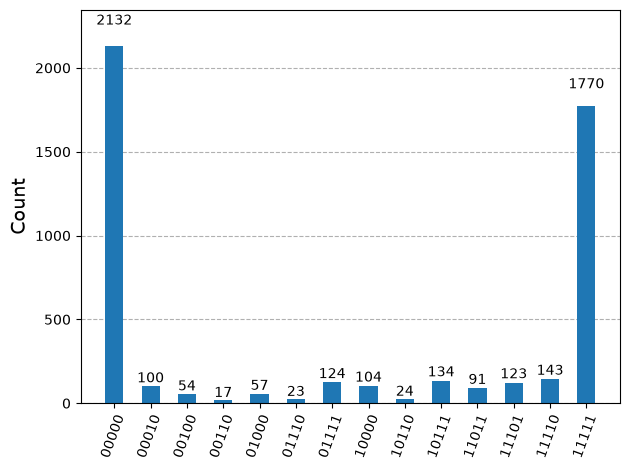

In [5]:
from qiskit.visualization import plot_histogram

# Run circuit
SHOTS = 5000

job = backend.run(qc_transpiled, shots=SHOTS)
results = job.result().get_counts()


# Plot result
print(results)

result_clean = {key: count for key, count in results.items() if count > 15}
display(plot_histogram(result_clean))